Universes for the purpose of expressing repeated structures.

Roulette and particle-splitting don't happen unless weight windows are present, which requires some additional steps to create and are not enabled by default. Hence, there is no analogue of MCNP's neutron importance construct (imp:n) here.

In [1]:
import sys
print(sys.executable)
print(sys.path)

import importlib.metadata
print(importlib.metadata.distribution("openmc"))

import openmc
print(openmc.__file__)

/home/jovibuca/anaconda3/envs/omc/bin/python
['/home/jovibuca/anaconda3/envs/omc/lib/python312.zip', '/home/jovibuca/anaconda3/envs/omc/lib/python3.12', '/home/jovibuca/anaconda3/envs/omc/lib/python3.12/lib-dynload', '', '/home/jovibuca/anaconda3/envs/omc/lib/python3.12/site-packages', '/home/jovibuca/openmc-plasma-source/src', '__editable__.openmc_plotter-0.5.1.dev9+gb5113a3d7.finder.__path_hook__']
/home/jovibuca/anaconda3/envs/omc/lib/python3.12/site-packages/openmc/__init__.py


<Axes: xlabel='x [cm]', ylabel='y [cm]'>

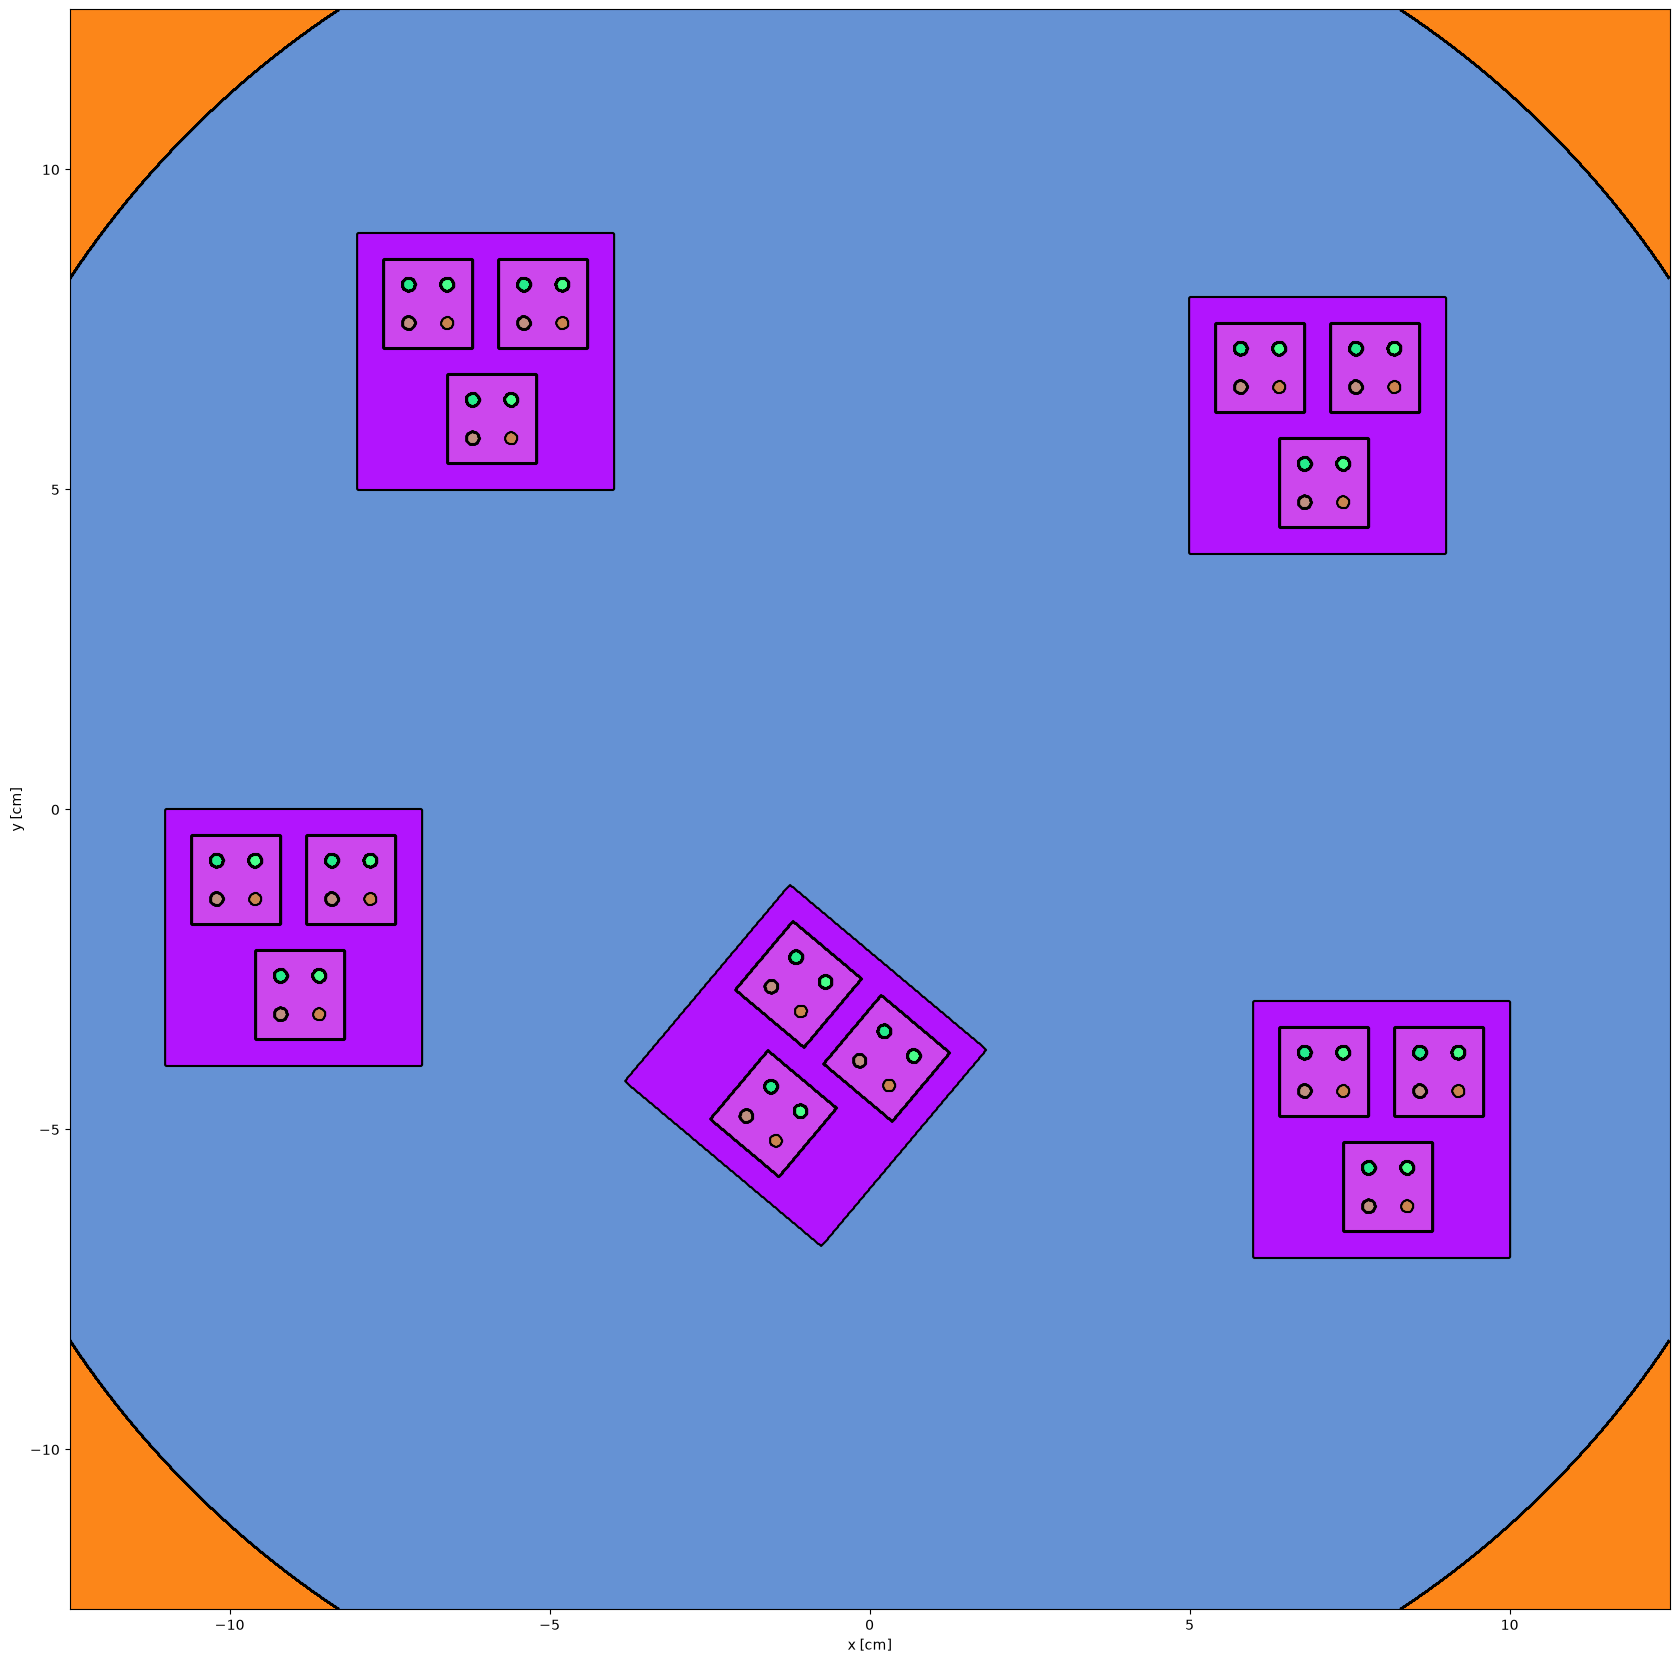

In [2]:
%run -i clean_script.py
import openmc 
import numpy as np

materials=openmc.Materials()
materials.cross_sections='/home/jovibuca/endf/endfb-viii.0-hdf5/cross_sections.xml'

carbon = openmc.Material()
carbon.add_nuclide('C12',1)
carbon.set_density('g/cc',0.5)
materials.append(carbon)

uranium=openmc.Material()
uranium.add_nuclide('U235',1)
uranium.set_density('g/cc',19)
materials.append(uranium)

# Surface definitions
s1 = openmc.XPlane(-2)
s2 = openmc.YPlane(2)
s3 = openmc.XPlane(2)
s4=openmc.YPlane(-2)
s5=openmc.ZPlane(-2)
s6=openmc.ZPlane(2)
s7=openmc.Sphere(r=15, boundary_type='vacuum')
s8=openmc.XPlane(-0.7)
s9=openmc.YPlane(0.7)
s10=openmc.XPlane(0.7)
s11=openmc.YPlane(-0.7)
s12=openmc.ZCylinder(r=0.1)

# Universe 2 definition (Four ZCylinders arranged as the corners of a square, to go inside the little boxes)
u2_base = -s12
u2_tr= [[-0.3, .3, 0], [0.3, 0.3, 0], [0.3, -0.3, 0], [-0.3, -0.3, 0]]
c12_region = u2_base.translate(u2_tr[0])
c12 = openmc.Cell(fill=uranium, region=c12_region)

c13_region = u2_base.translate(u2_tr[1])
c13 = openmc.Cell(fill=uranium, region=c13_region)

c14_region=u2_base.translate(u2_tr[2])
c14 = openmc.Cell(fill=uranium, region=c14_region)

c15_region=u2_base.translate(u2_tr[3])
c15 = openmc.Cell(fill=uranium, region=c15_region)

c16 = openmc.Cell(fill=carbon, region=~c12.region & ~c13.region & ~c14.region & ~c15.region)

u2 = openmc.Universe(cells=[c12,c13,c14,c15,c16])

c7 = openmc.Cell(fill=None,region=+s7)

# Universe 1 definition (Little boxes)
u1_base=+s8&-s9 & -s10 & +s11
u1_tr = [[-0.9, 0.9, 0], [0.9, 0.9, 0], [0.1, -0.9, 0]]
c8_region=u1_base.translate((-0.9,0.9,0))
c8 = openmc.Cell(fill=u2,region=c8_region)
c8.translation=(-0.9,0.9,0)

c9_region=u1_base.translate((0.9,0.9,0))
c9 = openmc.Cell(fill=u2,region=c9_region)
c9.translation=(0.9,0.9,0)

c10_region=u1_base.translate((0.1,-0.9,0))
c10 = openmc.Cell(fill=u2,region=c10_region)
c10.translation=(0.1,-0.9,0)

c11 =openmc.Cell(fill=uranium, region=~c8.region & ~c9.region & ~c10.region)
u1 = openmc.Universe(cells=[c8,c9,c10,c11])

# Fill in big boxes
tr2 = [-6,7,1.2]
tr3 = [7, 6, 1.1]
tr4 = [8, -5, 1.4]
tr5  = [-1,-4,1]
tr5_rotate = [0,0,-40]
tr5_effect = [-1*np.cos(40), -4*np.sin(40),1]
tr6 = [-9,-2,1.3]
big_box_TRs = [tr2,tr3,tr4,tr5_effect,tr6]

base = +s1&-s2&-s3&+s4&+s5&-s6

c2_region = base.translate(tr2)
c2 = openmc.Cell(fill=u1, region=c2_region)
c2.translation = tr2

c3_region = base.translate(tr3)
c3 = openmc.Cell(fill=u1, region=c3_region)
c3.translation = tr3

c4_region = base.translate(tr4)
c4 = openmc.Cell(fill=u1, region=c4_region)
c4.translation = tr4

c5_region= base.rotate(tr5_rotate)
c5_region=c5_region.translate(tr5)
c5=openmc.Cell(fill=u1,region=c5_region)
c5.rotation=tr5_rotate
c5.translation=tr5

c6_region=base.translate(tr6)
c6=openmc.Cell(fill=u1,region=c6_region)
c6.translation=tr6

c1 = openmc.Cell(fill=carbon,region=-s7&~c2.region&~c3.region&~c4.region&~c5.region&~c6.region) 

geometry=openmc.Geometry([c1,c2,c3,c4,c5,c6,c7,c8,c9,c10,c11,c12,c13,c14,c15,c16])
w = 25
px = 1600
geometry.plot(width=(w,w),pixels=(px,px),basis='xy',color_by='cell',outline=True)

In [3]:
settings=openmc.Settings()
settings.particles = 1000
settings.batches = 100
settings.run_mode = 'fixed source'

model = openmc.model.Model()
model.settings=settings
model.geometry=geometry
model.materials=materials

geometry.export_to_xml()

When defining tallies and sources, it sometimes is more helpful to know which ids the Python API has assigned the various features.

In the MCNP example, the source definition is extensive.

However, what it is actually describing is fairly simple; it is just asking for all of the small Z-cylinders in each box. 

In [4]:
source = openmc.IndependentSource()

source.spatial = []
spatial_count = 0 # should be 60
for big_tr in big_box_TRs:
    for mid_box_tr in u1_tr:
        for cyl_tr in u2_tr:
            origin = np.array(cyl_tr) + np.array(mid_box_tr) + np.array(big_tr)
            source.spatial.append(openmc.stats.cylindrical_uniform(
                r_outer = 0.1, # SI5
                r_inner = 0,
                height = 4, # SI6
                origin = origin) #SI7
                                 )
            #print(origin)
            spatial_count += 1
print(spatial_count)

source.energy = openmc.stats.Discrete(
    x=np.array([1, 3, 4, 5, 6, 7 , 8, 9, 11])*1e6,
    p=[0, 0.22, 0.08, 0.25, 0.18, 0.07, 0.11, 0.05, 0.05],
    bias = [0, 0.05, 0.05, 0.1, 0.1, 0.2, 0.2, 0.1, 0.2],
)

settings.source = source

# There is a 0.1 cutoff in energy:
settings.cutoff = {'energy_neutron':0.1e6}

model.settings = settings

60


The filters defined below are a CellFilter and EnergyFilter. The former will create a bin for every single uniquely defined cell; for instance, this means that the c12 bin will be the average of flux for all instances of c12. In total, there will be 9 cell bins. 

If one wanted a bin for every single instance of a cell, use `openmc.CellInstanceFilter`.

In [5]:
tallies = openmc.Tallies()

f4 = openmc.Tally() 
f4.name = 'f4'
f4_cbins=openmc.CellFilter([c2,c3,c4,c5,c6,c12,c13,c14,c15])
f4_ebins= openmc.EnergyFilter(np.array([1,3,5,7,9,11,13])*1e6)
f4.filters = [f4_cbins,
              f4_ebins]
# This tally will, without modification, report particle-cm/source. One would need to normalize w.r.t. cell volume.
f4.scores = ['flux'] 
f4.estimator = 'tracklength' # OpenMC usually defaults to tracklength for flux tallies
tallies.append(f4)

# This following tally is not in the MCNP model, but would be useful for visualization. 
#f4_mesh_tally = openmc.Tally()
#f4.name = 'mesh-flux'
#f4.filters = openmc.MeshFilter()(

model.tallies = tallies

In [6]:
%cat geometry.xml

<?xml version='1.0' encoding='UTF-8'?>
<geometry>
  <cell id="1" material="2" region="-13" universe="1"/>
  <cell id="2" material="2" region="-14" universe="1"/>
  <cell id="3" material="2" region="-15" universe="1"/>
  <cell id="4" material="2" region="-16" universe="1"/>
  <cell id="5" material="1" region="13 14 15 16" universe="1"/>
  <cell id="6" material="void" region="7" universe="3"/>
  <cell id="7" fill="1" region="17 -18 -19 20" translation="-0.9 0.9 0.0" universe="2"/>
  <cell id="8" fill="1" region="21 -22 -23 24" translation="0.9 0.9 0.0" universe="2"/>
  <cell id="9" fill="1" region="25 -26 -27 28" translation="0.1 -0.9 0.0" universe="2"/>
  <cell id="10" material="2" region="(-17 | 18 | 19 | -20) (-21 | 22 | 23 | -24) (-25 | 26 | 27 | -28)" universe="2"/>
  <cell id="11" fill="2" region="29 -30 -31 32 33 -34" translation="-6.0 7.0 1.2" universe="3"/>
  <cell id="12" fill="2" region="35 -36 -37 38 39 -40" translation="7.0 6.0 1.1" universe="3"/>
  <cell id="13" fill="2" re

In [7]:
plots = openmc.Plots()

level = 1
w = 25
px = 1600
plot = openmc.SlicePlot()
plot.basis = 'xy'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (px, px)
plot.color_by= 'cell'
#plot.level=level
plots.append(plot)

model.plots=plots
model.export_to_xml()

Here's the output from openmc-plotter:

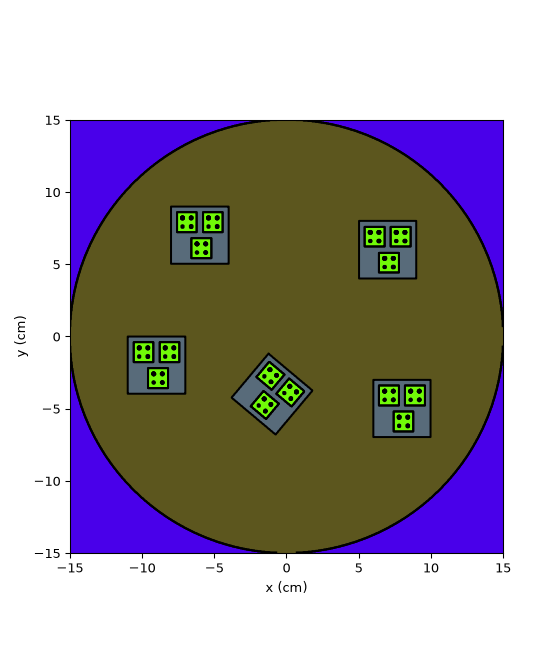

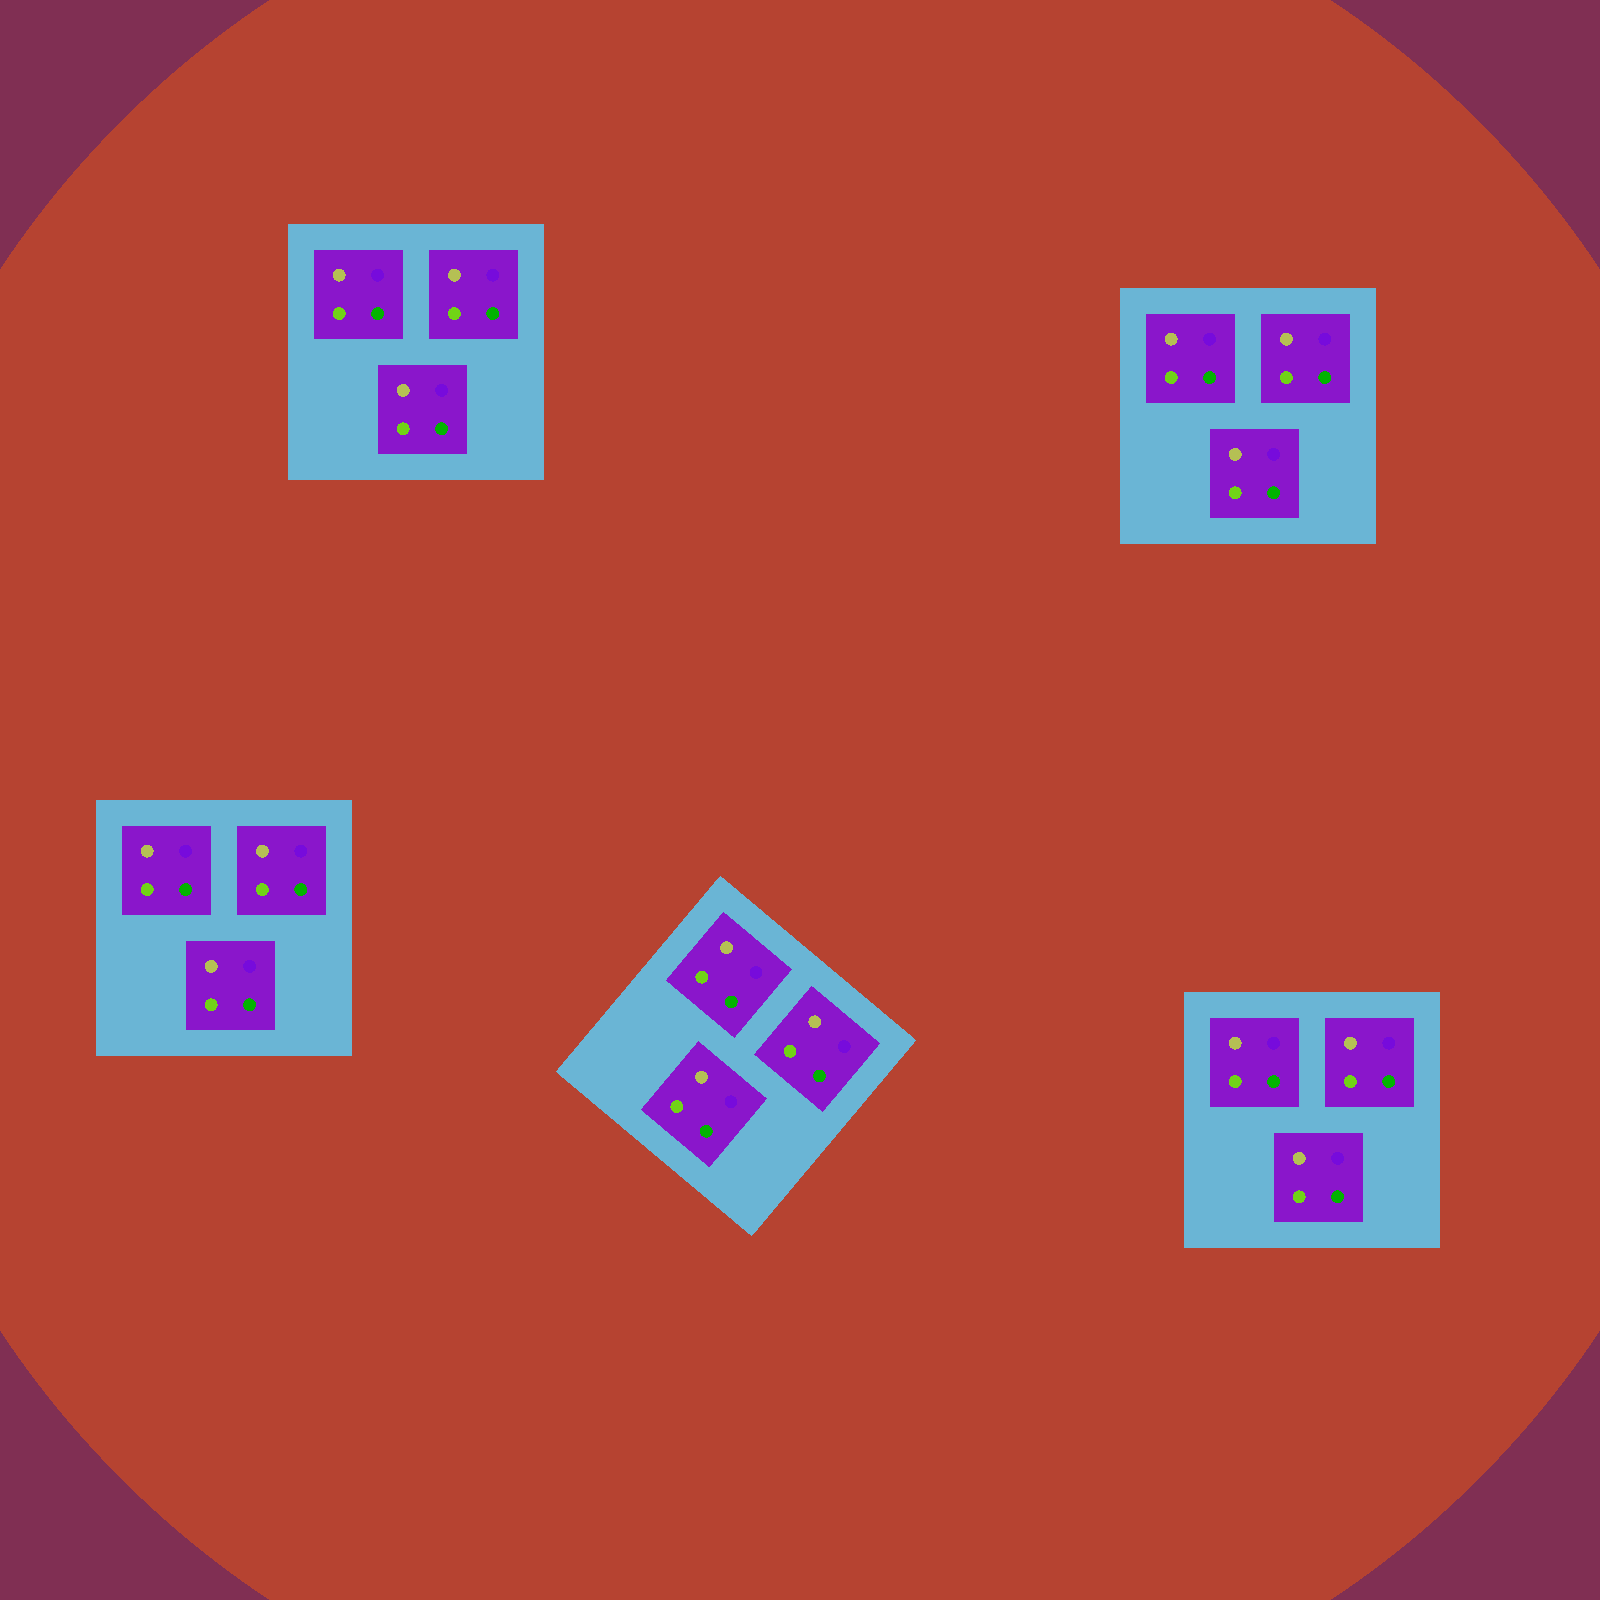

In [8]:
openmc.plot_inline(plots)

In [9]:
sp_filename = model.run()

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

The MCNP example calls for `fq f e`, which basically controls the order of how tally results are printed. 

   cell nuclide score     mean  std. dev.
0    11   total  flux 7.76e-02   2.45e-03
1    12   total  flux 7.61e-02   2.26e-03
2    13   total  flux 7.44e-02   2.11e-03
3    14   total  flux 3.59e-01   5.19e-03
4    15   total  flux 7.90e-02   2.45e-03
5     1   total  flux 4.46e-03   1.25e-04
6     2   total  flux 4.10e-03   1.39e-04
7     3   total  flux 3.67e-03   1.34e-04
8     4   total  flux 3.63e-03   1.18e-04
   energy low [eV]  energy high [eV] nuclide score     mean  std. dev.
0         1.00e+06          3.00e+06   total  flux 3.09e-02   1.77e-03
1         3.00e+06          5.00e+06   total  flux 2.46e-02   1.49e-03
2         5.00e+06          7.00e+06   total  flux 1.24e-02   6.97e-04
3         7.00e+06          9.00e+06   total  flux 7.46e-03   3.83e-04
4         9.00e+06          1.10e+07   total  flux 2.26e-03   1.29e-04
5         1.10e+07          1.30e+07   total  flux 9.44e-06   9.44e-06


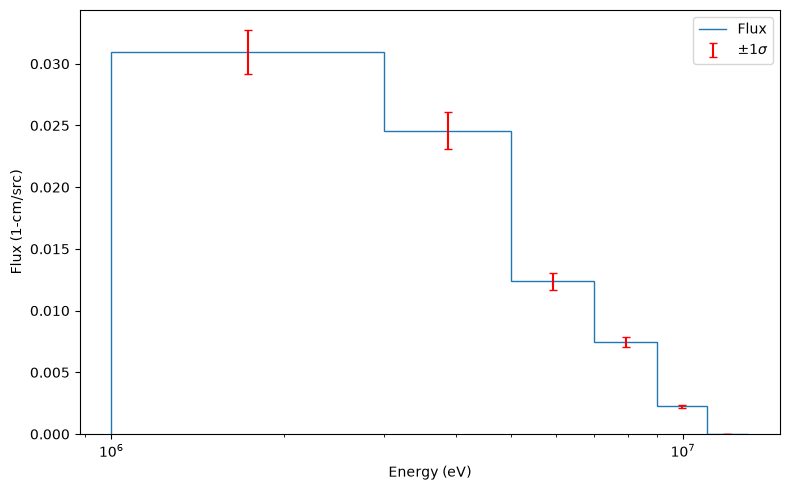

In [10]:
import matplotlib.pyplot as plt
with openmc.StatePoint(sp_filename) as sp:
    tally =  sp.get_tally(name='f4')
    df = tally.get_pandas_dataframe()
    
    #res = tally.get_slice(filters=[openmc.EnergyFilter],filter_bins=[filter_bin])

    cfilter_bin = [tuple(f4_cbins.bins)]
    #res = tally.get_slice(filters=[openmc.CellFilter],filter_bins=filter_bin,squeeze=True)
    
    efilter_bin = tuple([tuple(tuple([b[0],b[1]])) for b in f4_ebins.bins ],)
    cell_flux = tally.summation(filter_type=openmc.EnergyFilter,filter_bins=efilter_bin,remove_filter=True) # means integrate over all energies)
    eres = cell_flux.get_pandas_dataframe()
    print(eres)
    energy_flux = tally.summation(filter_type=openmc.CellFilter,filter_bins=cfilter_bin,remove_filter=True)
    cres=energy_flux.get_pandas_dataframe()
    print(cres)

    E_low = cres["energy low [eV]"].to_numpy()
    E_high = cres["energy high [eV]"].to_numpy()
    mean = cres["mean"].to_numpy()
    std = cres["std. dev."].to_numpy()

    edges = np.concatenate([E_low, [E_high[-1]]])

    plt.figure(figsize=(8,5))
    plt.stairs(mean, edges, label="Flux")

    centers = np.sqrt(E_low * E_high)

    plt.errorbar(centers,
                 mean,
                 yerr=std,
                 fmt='none',
                 capsize=3,
                 color='red',
                 label=r'$\pm 1\sigma$')
    plt.xscale("log")
    plt.xlabel("Energy (eV)")
    plt.ylabel('Flux (1-cm/src)')
    plt.legend()
    plt.tight_layout()
    plt.show()
   # print(res.get_pandas_dataframe())